In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score

In [2]:
from sklearn.svm import SVC

## 서포트 벡터 머신 알고리즘에 사용할 데이터를 읽어와서 학습 데이터와 테스트 데이터로 나눈다.

In [3]:
basketball_stat_df = pd.read_csv('./data/basketball_stat.csv')
basketball_stat_df.drop(['Player', '2P', 'AST', 'STL'], axis=1, inplace=True)
train, test = train_test_split(basketball_stat_df, train_size=0.8)
print(train.shape, test.shape)
train.head()

(80, 4) (20, 4)


,Pos,3P,TRB,BLK
69,C,0.0,4.2,0.8
30,C,1.4,6.3,1.3
65,SG,2.3,3.6,0.5
9,C,0.0,7.0,1.1
55,SG,1.5,4.0,0.1


## 커널 트릭(kernel trick)

선형으로 분리할 수 없는 복잡한 비선형 데이터를 저차원 벡터 공간에서 고차원 벡터 공간으로 옮겨줌으로써 선형 분리가 가능하게 결정 경계를 찾는 방법이 있다.

저차원의 데이터를 고차원의 데이터로 옮겨주는 함수를 매핑 함수라 하고 매핑 함수로 많은 양의 데이터를 저차원에서 고차원으로 옮기기에는 연산량이 너무 많아져서 현실적으로 사용하기 어렵다. 실제로 데이터를 고차원으로 보내지는 않지만 보낸것과 동일한 효과를 줘서 빠른 속도로 결정 경계를 찾는 방법이 고안되었으며 이를 커널 트릭이라고 한다.

## 최적의 서포트 벡터 머신 파라미터를 찾는다.

서포트 벡터 머신은 커널 트릭에 사용될 커널 함수(kernel), 마진의 너비를 조절하는 파라미터(C), 결정 경계의 곡률을 조정하는 파라미터(gamma)를 알아야 한다.

```
커널 종류 | 설명 및 특징                                                | 주요 활용처
linear    | 데이터를 변형하지 않고 원본 공간 그대로 사용한다.           | 텍스트 분류
          | 연산 속도가 가장 빠르다.                                    | 특성(Feature)의 수가 매우 많은 고차원 데이터
poly      | 다항식 형태로 차원을 확장하여 비선형 관계를 학습한다.       | 이미지 처리, 자연어 처리 등
          | 매개변수 차수에 따라 복잡도가 달라진다.                     |
rbf       | 무한한 차원의 공간으로 데이터를 매핑한다.                   | 일반적인 비선형 분류 및 회귀 문제(기본값)
          | 가장 널리 쓰이며 성능이 강력하지만, 과적합에 주의해야 한다. |
sigmoid   | 신경망의 활성화 함수와 유사한 형태를 띤다.                  | 신경망 기반 모델과 유사한 특성을 낼 때
```

최적의 파라미터를 얻어내기 위해서 GridSearchCV를 import 한다.

In [4]:
from sklearn.model_selection import GridSearchCV

kernel은 기본값으로 사용되는 일반적인 비선형 분류 및 회귀 문제에 사용하는 rbf 커널로 고정하고 최적의 C, gamma 값을 가지는 GridSearchCV 객체를 리턴하는 함수

In [5]:
def svm_param_selection(x_train, y_train, nfold):
    # 마진과 gamma 값의 후보를 임의로 지정한다.
    svm_param = [{
        'kernel': ['rbf'],
        'C': [0.01, 0.1, 1, 10, 100, 1000],
        'gamma': [0.00001, 0.0001, 0.001, 0.01, 0.1, 1]
    }]
    # GridSearchCV 클래스의 생성자로 서포트 벡터 머신 모델, 마진과 gamma 값의 후보, 폴드 개수를 넘겨서 객체를 만든다.
    grid_search = GridSearchCV(SVC(), svm_param, cv=nfold)
    # GridSearchCV 모델을 학습시킨다.
    grid_search.fit(x_train, y_train)
    return grid_search

GridSearchCV 객체에서 `best_score_`는 최고 점수,`best_params_`는 최고 점수를 낸 파라미터, `best_estimator_`는 최고 점수를 낸 파라미터를 사용하는 모델을 얻어올 수 있다.

In [6]:
# 3P와 BLK가 3P와 TRB에 비해서 Pos을 더 확실하게 구분할 수 있기 때문에 3P와 BLK를 학습 데이터로 사용한다.
x_train = train[['3P', 'BLK']]
y_train = train['Pos']
grid_search = svm_param_selection(x_train, y_train, 10)
print(f'최고 점수: {grid_search.best_score_}')
print(f'최고 점수를 낸 파라미터: {grid_search.best_params_}, {grid_search.best_params_["C"]}, {grid_search.best_params_["gamma"]}')
print(f'최고 점수를 낸 파라미터를 가진 SVM 모델: {grid_search.best_estimator_}')

최고 점수: 0.9625
최고 점수를 낸 파라미터: {'C': 0.1, 'gamma': 1, 'kernel': 'rbf'}, 0.1, 1
최고 점수를 낸 파라미터를 가진 SVM 모델: SVC(C=0.1, gamma=1)


## 결정 경계 시각화

In [7]:
# 최고 점수를 낸 파라미터를 이용해서 시각화 할 마진 너비(C)의 후보들을 지정한다.
C_list = []
C_list.append(grid_search.best_params_['C'] * 0.01)
C_list.append(grid_search.best_params_['C']) # 최적의 C
C_list.append(grid_search.best_params_['C'] * 100)
print(C_list)

# 최고 점수를 낸 파라미터를 이용해서 시각화 할 결정 경계의 곡률(gamma)의 후보들을 지정한다.
gamma_list = []
gamma_list.append(grid_search.best_params_['gamma'] * 0.01)
gamma_list.append(grid_search.best_params_['gamma']) # 최적의 gamma
gamma_list.append(grid_search.best_params_['gamma'] * 100)
print(gamma_list)

[0.001, 0.1, 10.0]
[0.01, 1, 100]


In [8]:
# 시각화를 위해서 Pos를 숫자(C: 0, SG:1)로 표현한다.
position = []
for i in y_train:
    position.append(0 if i == 'C' else 1)
print(position)

[0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1]


In [9]:
# 최적의 파라미터 후보들을 조합해서 학습한 SVM 모델들을 저장한다.
models = []
for c in C_list:
    for g in gamma_list:
        # 최적의 파라미터 후보들을 조합해서 SVM 모델을 만든다.
        model = SVC(C=c, gamma=g)
        # 최적의 파라미터 후보들을 조합해서 만든 SVM 모델을 학습시킨다.
        model.fit(x_train, y_train)
        # 최적의 파라미터 후보들을 조합해서 만든 SVM 모델을 학습시킨 SVM 모델을 저장한다.
        models.append([c, g, model])
models

[[0.001, 0.01, SVC(C=0.001, gamma=0.01)],
 [0.001, 1, SVC(C=0.001, gamma=1)],
 [0.001, 100, SVC(C=0.001, gamma=100)],
 [0.1, 0.01, SVC(C=0.1, gamma=0.01)],
 [0.1, 1, SVC(C=0.1, gamma=1)],
 [0.1, 100, SVC(C=0.1, gamma=100)],
 [10.0, 0.01, SVC(C=10.0, gamma=0.01)],
 [10.0, 1, SVC(C=10.0, gamma=1)],
 [10.0, 100, SVC(C=10.0, gamma=100)]]

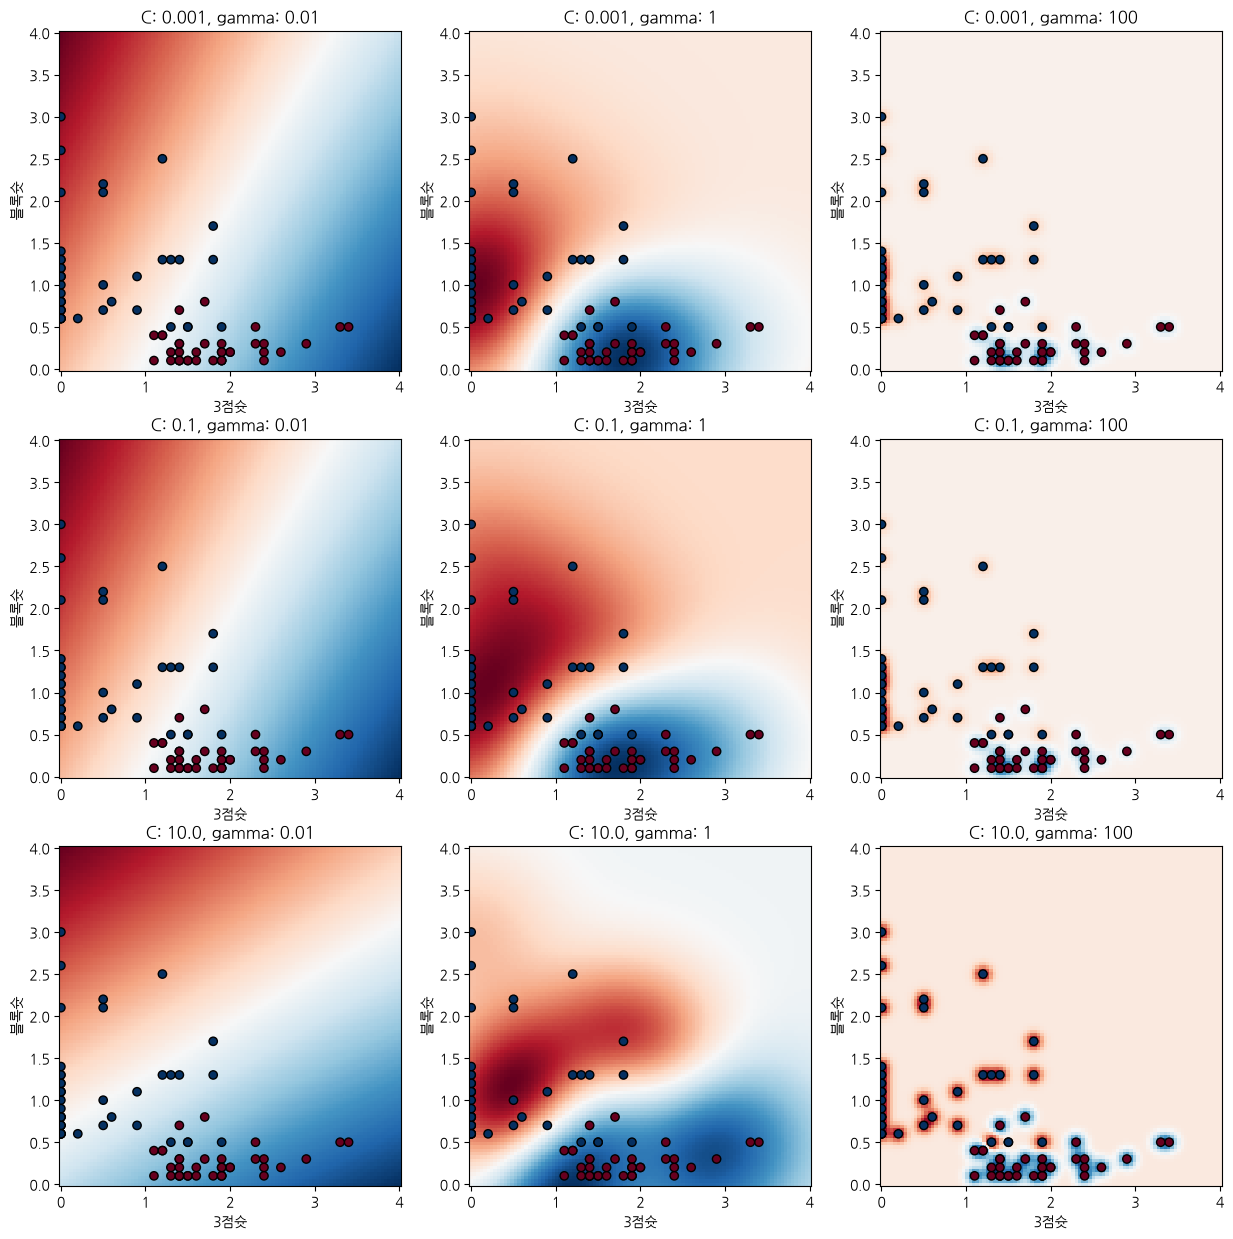

In [10]:
plt.figure(figsize=(15, 15))
xx, yy = np.meshgrid(np.linspace(0, 4, 100), np.linspace(0, 4, 100))
for i, (c, g, model) in enumerate(models):
    z = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
    z = z.reshape(xx.shape)
    plt.subplot(len(C_list), len(gamma_list), i + 1)
    plt.pcolormesh(xx, yy, -z, cmap=plt.cm.RdBu_r)
    plt.scatter(x=x_train['3P'], y=x_train['BLK'], c=position, cmap=plt.cm.RdBu_r, edgecolors='k')
    plt.title(f'C: {c}, gamma: {g}')
    plt.xlabel('3점슛')
    plt.ylabel('블록슛')
plt.show()

위의 9개 차트 중에서 정가운데 차트가 GridSearchCV 객체를 통해서 얻은 최적의 C, gamma 값을 사용해서 학습한 SVM 모델이며 균등하게 두 그룹이 분할된 것을 확인할 수 있다. 가로 방향으로 보면 gamma 값의 크기에 따라서 결정 경계의 곡률 변화를 확인할 수 있고 세로 방향으로 보면 C값의 크기에 따른 결정 경계의 위치 변화를 볼 수 있다.

## 최적의 파라미터로 SVM 모델을 만들고 테스트 한다.

In [11]:
x_test = test[['3P', 'BLK']]
y_test = test['Pos']
model = SVC(C=1, gamma=1, kernel='rbf')
model.fit(x_train, y_train)
predict = model.predict(x_test)
accuracy = accuracy_score(y_test, predict)
print(f'정확도: {accuracy:.2%}')

정확도: 95.00%


In [12]:
pd.DataFrame({'실제값': y_test, '예측값': predict})

,실제값,예측값
44,C,C
96,SG,C
88,SG,SG
86,SG,SG
73,SG,SG
90,C,C
11,C,C
13,SG,SG
53,C,C
8,SG,SG


In [15]:
classification = classification_report(y_test, predict)
print(classification)

              precision    recall  f1-score   support

           C       0.89      1.00      0.94         8
          SG       1.00      0.92      0.96        12

    accuracy                           0.95        20
   macro avg       0.94      0.96      0.95        20
weighted avg       0.96      0.95      0.95        20



# 완성된 모델 사용하기

In [16]:
x = {'3P': [0, 3.9], 'TRB': [1, 0.1], 'BLK': [7.7, 0.3], 'Pos': ['C', 'SG']}
df = pd.DataFrame(x)
df

,3P,TRB,BLK,Pos
0,0.0,1.0,7.7,C
1,3.9,0.1,0.3,SG


In [19]:
x_test = df[['3P', 'BLK']]
y_test = df['Pos']

In [20]:
predict = model.predict(x_test)
print(predict)
accuracy = accuracy_score(y_test, predict)
print(f'정확도: {accuracy:.2%}')

['C' 'SG']
정확도: 100.00%


In [21]:
pd.DataFrame({'실제값': y_test, '예측값': predict})

,실제값,예측값
0,C,C
1,SG,SG
